In [1]:
import pandas as pd
df=pd.read_csv("Cancer_Prediction.csv")

In [2]:
df.dtypes

id                           int64
diagnosis                   object
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_worst          float64
concavity_worst     

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [ ]:


# 1. Features
X = df.drop(columns=["id", "diagnosis", "Unnamed: 32"])

# 2. Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Create K-Means model
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# 4. Train K-Means
kmeans.fit(X_scaled)

# 5. Get cluster assignments
clusters = kmeans.labels_ #kmeans.labels_ contains the cluster assigned to every row.

# 6. Add cluster to dataframe
df["cluster"] = clusters

print(df[["diagnosis", "cluster"]].head(10))

  diagnosis  cluster
0         M        1
1         M        1
2         M        1
3         M        1
4         M        1
5         M        1
6         M        1
7         M        1
8         M        1
9         M        1


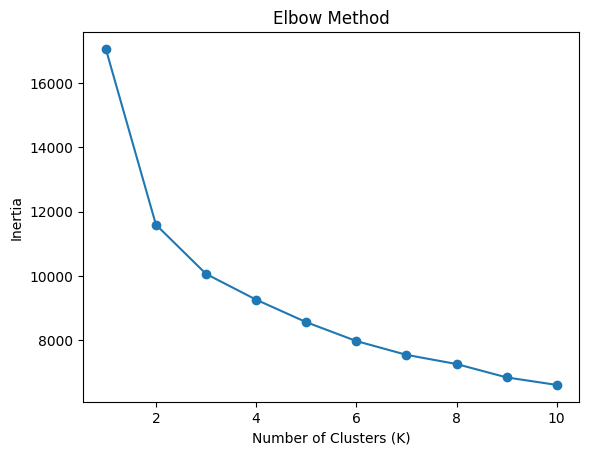

In [5]:
import matplotlib.pyplot as plt

inertia = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [6]:
# Print diagnosis and assigned cluster
print(df[["diagnosis", "cluster"]])

# Or print only cluster numbers
print(df["cluster"])

    diagnosis  cluster
0           M        1
1           M        1
2           M        1
3           M        1
4           M        1
..        ...      ...
564         M        1
565         M        1
566         M        1
567         M        1
568         B        0

[569 rows x 2 columns]
0      1
1      1
2      1
3      1
4      1
      ..
564    1
565    1
566    1
567    1
568    0
Name: cluster, Length: 569, dtype: int32


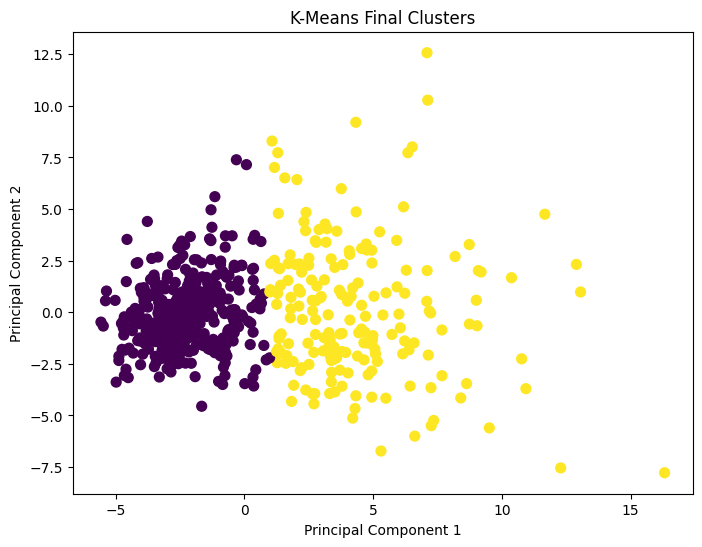

In [7]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce scaled features to 2 dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Scatter plot
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["cluster"],
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Final Clusters")

plt.show()

In [ ]:
# K-Means — Unsupervised Learning

# Now let's use the same cancer dataset.

# But this time we tell K-Means:

# "Don't look at diagnosis. Just look at the measurements and find 2 groups."